In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import numpy as np
import h5py
import matplotlib.pyplot as plt
from turbos.sim.vpic.vpic import VPIC, load_info
from turbos.filter import kfilter
from turbos.pressure_strain import pressure_strain

In [3]:
from turbos.sim.vpic.vpic import VPIC

run = VPIC(
    info_file="/work/space_plasma/users/goodwill/KH/info",
    data_dirs={
        "fields": "/lustre/scratch/goodwill/KH/field_hdf5",
        "hydro": "/lustre/scratch/goodwill/KH/hydro_hdf5",
    },
)

# ds = run.load_step(
#     480000,
#     ["B", "E", "ne", "ni", "Je", "ue", "ui", "Te", "Pe"],
# )

In [4]:
# print(ds.info)
print(run.nx, run.ny, run.nz)  # 1200, 2400, 1
print(run.lx, run.ly, run.lz)  # 125, 250, 0.1041667 — in d_e
print(run.dx, run.dy, run.dz)  # ≈ 0.1041667 each

1200 2400 1
125.0 250.0 0.1041667
0.1041667 0.1041667 0.1041667


In [5]:
import xarray as xr
from pathlib import Path

# ds.close()

results = []
kf = 5

t = [140000, 240000, 320000, 480000]

for i in range(4):
    print(f"Processing timestep {t[i]}")

    ds = run.load_step(t[i], ['Pe', 'ue', 'Pi', 'ui'])
    # print(ds)

    Pe = kfilter(ds['Pe'], kf)
    ue = kfilter(ds['ue'], kf)
    Pi = kfilter(ds['Pi'], kf)
    ui = kfilter(ds['ui'], kf)

    pse = pressure_strain(Pe, ue)
    psi = pressure_strain(Pi, ui)

    ds_ps = xr.Dataset({
        'PiD_e': pse['PiD'],
        'pth_e': pse['pth'],
        'PiD_i': psi['PiD'],
        'pth_i': psi['pth'],
    })

    # Save normalized time as dimension coordinate
    ds_ps = ds_ps.expand_dims(
        time=[ds.attrs['time']]
    )

    # Save additional time information
    ds_ps = ds_ps.assign_coords(
        time_simulation=('time', [ds.attrs['time_simulation']]),
        step=('time', [ds.attrs['step']])
    )
    results.append(ds_ps)

# Combine all timesteps
ds_all = xr.concat(results, dim='time')

# Save as NetCDF
ds_all.attrs['kf'] = kf
path = Path("~/turbos/projects/KHI_2D/data/PS.nc").expanduser()
ds_all.to_netcdf(path, mode="w")

Processing timestep 140000
Processing timestep 240000


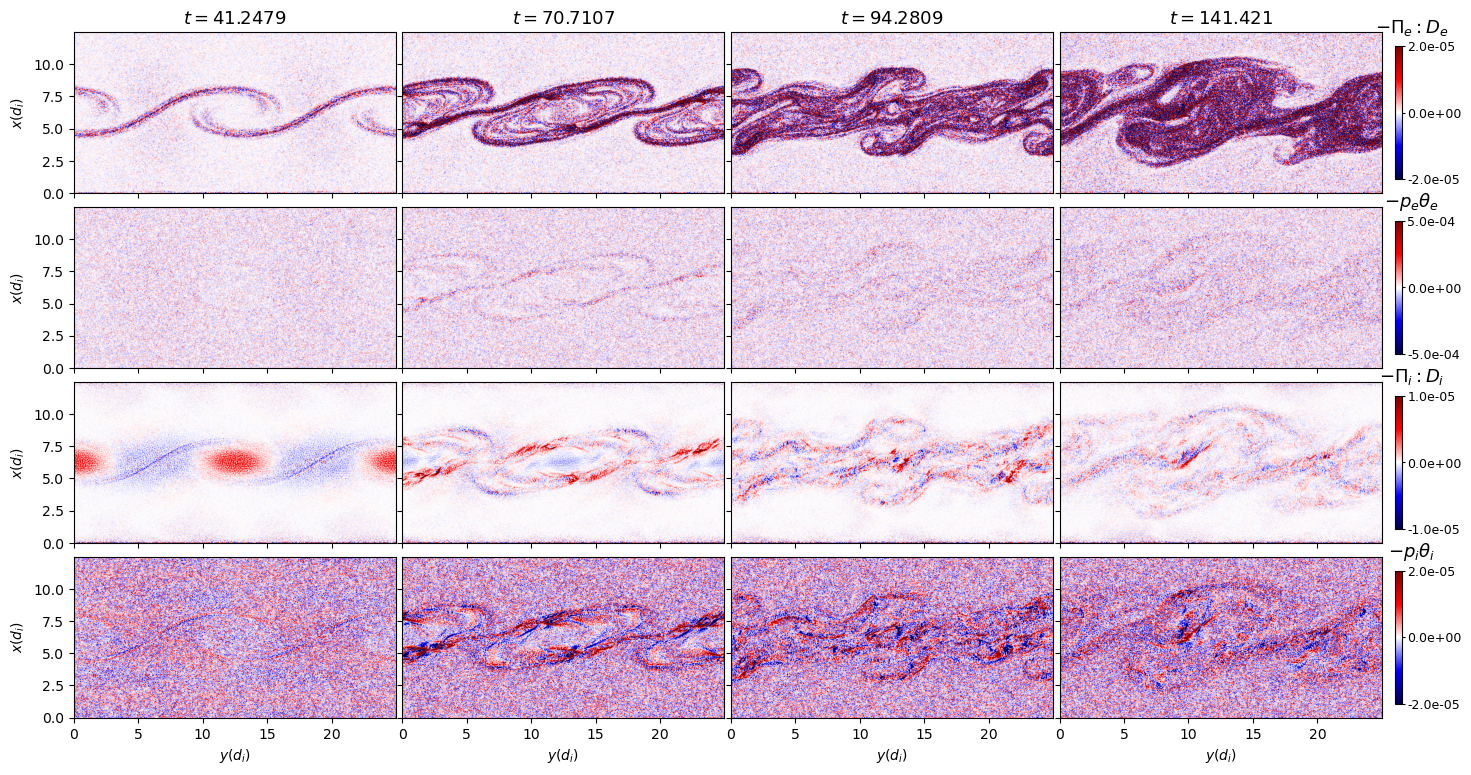

In [ ]:
import matplotlib.pyplot as plt
import xarray as xr

ds = xr.open_dataset("~/turbos/projects/KHI_2D/data/PS.nc")

variables = ["PiD_e", "pth_e", "PiD_i", "pth_i"]

labels = [
    r"$-\Pi_e:D_e$",
    r"$-p_e\theta_e$",
    r"$-\Pi_i:D_i$",
    r"$-p_i\theta_i$",
]

vmag = [2e-5, 5e-4, 1e-5, 3e-5]

fig, ax = plt.subplots(
    4, 4,
    figsize=(16, 8),
    sharex=True,
    sharey=True,
    layout=None,
    gridspec_kw={
        "wspace": 0.02,
        "hspace": 0.02
    }
)

fig.subplots_adjust(
    left=0.07,
    right=0.90,
    bottom=0.08,
    top=0.95,
    wspace=0.02,
    hspace=0.02
)

for row, (var, label, vmax) in enumerate(zip(variables, labels, vmag)):

    for col in range(4):

        da = ds[var].isel(time=col)

        im = ax[row, col].imshow(
            da.values,
            cmap="seismic",
            origin="lower",
            interpolation="auto",
            extent=[
                ds.y.values[0]/10, ds.y.values[-1]/10,
                ds.x.values[0]/10, ds.x.values[-1]/10
            ],
            vmin=-vmax,
            vmax=vmax,
            aspect="equal"
        )

        # Time labels across top
        if row == 0:
            ax[row, col].set_title(
                rf"$t = {ds.time.values[col]:g}$",
                fontsize=13
            )

        # Spatial axes
        if row == 3:
            ax[row, col].set_xlabel(r"$y(d_i)$")

        if col == 0:
            ax[row, col].set_ylabel(r"$x(d_i)$" )


    exponent = int(np.floor(np.log10(vmax)))
    scale = 10**exponent

    cbar = fig.colorbar(
        im,
        ax=ax[row, :],
        fraction=0.005,
        pad=0.01,
        ticks=[-vmax, 0, vmax],
        format="%.1e"
    )

    cbar.ax.tick_params(labelsize=9, pad=2, length=2)
    cbar.ax.set_title(labels[row], fontsize=13, pad=10, x=2.5)

plt.savefig("/home/2480/turbos/projects/KHI_2D/fig/PS.png", dpi=300)
plt.show()